# Tiedonkäsittely Pythonilla (4 op)
#### Tekijä: Roni Pihajoki

# Työkalujen lisääminen, datasetin hakeminen & taulukon perustietoja


Ensin on tuloste rivien & sarakkeiden määristä <br>
Sen jälkeen on tuloste taulukon kolmesta ensimmäisestä rivistä <br>
Tästä näemme sarakeotsikot & esimerkit arvoista, joita taulukko sisältää <br>
Tämän pohjalta saamme ajatuksen, mitä dataa meillä on & mitä kaikkea voimme sillä tehdä <br>

In [2706]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency

%matplotlib inline

df = pd.read_csv('WorkPlaceSatisfactionSurveyData.csv', encoding='utf-8')

In [2707]:
print("Rivien lukumäärä: ",df.shape[0])
print("Sarakkeiden lukumäärä: ",df.shape[1])
print()
print("Tietoja taulukost:")
df.info()
print()
print("Kolme ensimmäistä riviä:")
df.head(3)


Rivien lukumäärä:  82
Sarakkeiden lukumäärä:  16

Tietoja taulukost:
<class 'pandas.DataFrame'>
RangeIndex: 82 entries, 0 to 81
Data columns (total 16 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   number                  82 non-null     int64  
 1   gender                  82 non-null     int64  
 2   age                     82 non-null     int64  
 3   family                  82 non-null     int64  
 4   education               81 non-null     float64
 5   years_of_service        80 non-null     float64
 6   salary                  82 non-null     int64  
 7   sat_management          82 non-null     int64  
 8   sat_colleques           81 non-null     float64
 9   sat_workingEnvironment  82 non-null     int64  
 10  sat_salary              82 non-null     int64  
 11  sat_tasks               82 non-null     int64  
 12  holidayCabin            20 non-null     float64
 13  gym                     9 non-null     

,number,gender,age,family,education,years_of_service,salary,sat_management,sat_colleques,sat_workingEnvironment,sat_salary,sat_tasks,holidayCabin,gym,muscleCare,healtcare
0,1,1,38,1,1.0,22.0,3587,3,3.0,3,3,3,NaN,NaN,NaN,NaN
1,2,1,29,2,2.0,10.0,2963,1,5.0,2,1,3,NaN,NaN,NaN,NaN
2,3,1,30,1,1.0,7.0,1989,3,4.0,1,1,3,NaN,NaN,NaN,1.0


---

# Projektin esittely


Minulle tuli seuraavat taustamuuttujat käsiteltäväksi:
- Education (Sarake E) = Luokkamuuttuja
- Salary (Sarake G) = Numeerinen muuttuja

Sat_sarakkeet ovat "tyytyväisyys" sarakkeita: <br>
- sat_management = Tämä kertoo kuinka tyytyväisiä johdosta ollaan
- sat_colleques = Tämä kertoo kuinka tyytyväisiä kolleegoista ollaan
- sat_workingEnvironment = Tämä kertoo kuinka tyytyväisiä työympäristöön ollaan
- sat_salary = Tämä kertoo kuinka tyytyväisiä palkkaan ollaan
- sat_tasks = Tämä kertoo kuinka tyytyväisiä työtehtäviin ollaan

Projektissa on ideana että käsitellään ensin jokainen taustamuuttuja & sat_muuttuja erikseen<br>
(esimerkiksi palkan keskiarvo, korkein palkka tai matalin palkka)<br>
Kun yksittäis analysointi on valmista, alamme tutkimaan taustamuuttujia & sat_muuttujia yhdessä<br>
(esimerkiksi miten korkeimman palkan saaja kokee tyytyväisyytensä työympäristöön)<br>
Yhteensä tehdään siis 10 yhdistelmä analysointia & 7 erillistä muuttuja kohtaista analysointia<br>

### Muuttujien arvojen selvennys
Education (Korkein suoritettu tutkinto):
- 1 = peruskoulu tutkinto
- 2 = toisen asteen tutkinto
- 3 = Kandidaatin tutkinto
- 4 = Maisterin tutkinto

Salary:
- Kuukauden palkka euroina

sat_muuttujat:
- Asteikolla 1-5
- 1 tarkoittaa erittäin tyytymätöntä
- 5 tarkoittaa erittäin tyytyväistä

## Taulukon siistiminen

Tiputetaan taulukosta meille turhat sarakkeet käyttäen .drop komentoa<br>
1. Tulostetaan tämän hetkisten sarakkeiden nimet
2. Tiputetaan sieltä 4 viimeistä saraketta, joita me emme käytä analyysissämme
3. Tulostetaan 3 ensimmäistä riviä uudestaan, josta näemme että sarakkeet on poistettu oikein

In [2708]:
df.columns

Index(['number', 'gender', 'age', 'family', 'education', 'years_of_service',
       'salary', 'sat_management', 'sat_colleques', 'sat_workingEnvironment',
       'sat_salary', 'sat_tasks', 'holidayCabin', 'gym', 'muscleCare',
       'healtcare'],
      dtype='str')

In [2709]:
df= df.drop(columns=['holidayCabin', 'gym', 'muscleCare', 'healtcare'])



In [2710]:
df.head(1)

,number,gender,age,family,education,years_of_service,salary,sat_management,sat_colleques,sat_workingEnvironment,sat_salary,sat_tasks
0,1,1,38,1,1.0,22.0,3587,3,3.0,3,3,3


Tiputetaan myös minulle turhat sarakkeet, joita en käytä omassa analyysissani

In [2711]:
df = df.drop(columns=['number', 'gender', 'age', 'family', 'years_of_service'])
df.head(1)

,education,salary,sat_management,sat_colleques,sat_workingEnvironment,sat_salary,sat_tasks
0,1.0,3587,3,3.0,3,3,3


### Vaihdetaan sarakkeiden nimet suomenkielisiksi

In [2712]:
df2 = df
df2.columns = ['koulutus', 'palkka', 'sat_johto', 'sat_kolleegat','sat_tyoYmparisto','sat_palkka','sat_tyoTehtavat']
df2.head(1)

,koulutus,palkka,sat_johto,sat_kolleegat,sat_tyoYmparisto,sat_palkka,sat_tyoTehtavat
0,1.0,3587,3,3.0,3,3,3


Tarkastellaan vielä tietoja taulukosta, kuten keskiarvoja, minimeitä ja maksimeita.

#### Tarkistetaan puuttuvat arvot

In [2713]:
df2.isnull().sum()

koulutus            1
palkka              0
sat_johto           0
sat_kolleegat       1
sat_tyoYmparisto    0
sat_palkka          0
sat_tyoTehtavat     0
dtype: int64

#### Taulukon uniikit arvot

In [2714]:
for var in df2:
    print(var, df2[var].unique())

koulutus [ 1.  2.  3.  4. nan]
palkka [3587 2963 1989 2144 2183 1910 2066 2768 2106 2651 2846 2808 3393 2691
 5225 2729 2925 2457 4874 3510 4446 1521 2223 1949 2340 6278 1559 2027
 2300 2534 1872 2261 2417 3119 2574 1715 5069 2495 3470 1598 1638 2612]
sat_johto [3 1 2 4 5]
sat_kolleegat [ 3.  5.  4.  2. nan]
sat_tyoYmparisto [3 2 1 5 4]
sat_palkka [3 1 2 4 5]
sat_tyoTehtavat [3 2 4 1 5]


---

# Taustamuuttujat

### Education Luokkamuuttuja


Mikä on korkein henkilön suorittama tutkinto<br>
- Peruskoulu tutkintoja korkeimpana suorituksena on 27 henkilöllä<br>
- Toisen asteen tutkintoja korkeimpana suorituksena on 30 henkilöllä<br>
- Kanditaatti tason tutkintoja korkeimpana suorituksena on 22 henkilöllä<br>
- Maisteri tason tutkintoja koirkaimpana suorituksena on 2 henkilöllä<br>
<br>
Vaihdetaan alla olevaan taulukkoon oikeat rivi otsikot


In [2715]:
dfe=pd.crosstab(df2['koulutus'], 'kpl')
dfe.index=['Peruskoulu', 'Toinen aste', 'Kanditaatti', 'Maisteri']
dfe.columns.name='Suoritetun tutkinnon taso'
dfe

Suoritetun tutkinnon taso,kpl
Peruskoulu,27
Toinen aste,30
Kanditaatti,22
Maisteri,2


Lasketaan suoritettujen tutkintojen määrä

In [2716]:
edu_caunt = sum(dfe['kpl'])
edu_caunt

81

Kaavio kuvaa tutkintojen jakaumaa

Text(0.5, 0, 'kpl, N = 81')

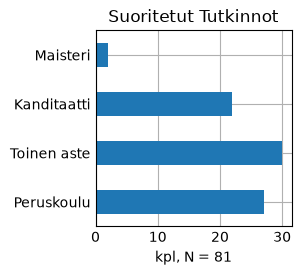

In [2717]:
dfe.plot.barh(legend = False)
plt.title('Suoritetut Tutkinnot')
plt.xlabel('kpl, N = 81')

Koulutusten keskiarvo, minimi, maksimi ja poikkeama <br>
Erikseen kirjattu mediaani & varianssi, koska ne puuttuvat taulukosta

In [2718]:
e_mediaani = df2['koulutus'].median()
e_varianssi = df2['koulutus'].var()

print("Koulutusten mediaani on  {:.0f}".format(e_mediaani))
print("Koulutusten varianssi on  {:.2f}".format(e_varianssi))

df2.describe()[["koulutus"] ]

Koulutusten mediaani on  2
Koulutusten varianssi on  0.71


,koulutus
count,81.000000
mean,1.987654
std,0.844006
min,1.000000
25%,1.000000
50%,2.000000
75%,3.000000
max,4.000000


Korkeamman koulutustason omaavien muut sarakkeet eli korkein suoritettu tutkinto on maisterin

In [2719]:
df2.nlargest(n=2, columns = 'koulutus')

,koulutus,palkka,sat_johto,sat_kolleegat,sat_tyoYmparisto,sat_palkka,sat_tyoTehtavat
16,4.0,5225,5,5.0,5,4,5
66,4.0,5069,3,4.0,3,2,2


Matalamman koulutustason omaavien muut sarakkeet eli korkein suoritettu tutkinto on peruskoulu

In [2720]:
df2.nsmallest(n=27, columns = 'koulutus')

,koulutus,palkka,sat_johto,sat_kolleegat,sat_tyoYmparisto,sat_palkka,sat_tyoTehtavat
0,1.0,3587,3,3.0,3,3,3
2,1.0,1989,3,4.0,1,1,3
3,1.0,2144,3,3.0,3,3,3
7,1.0,2066,3,5.0,3,1,3
8,1.0,2768,2,4.0,4,2,4
9,1.0,2106,3,2.0,1,1,1
10,1.0,2651,3,5.0,3,1,3
22,1.0,3510,4,4.0,4,4,4
27,1.0,2223,3,4.0,3,2,4
31,1.0,2925,4,4.0,4,3,4


Boxplot<br>
Tästä voimme nähdä miten 4.0 eli maisterin tutkinto on "poikkeama"<br>
81 tutkinnosta vain 2 on maistereita<br>

Text(0.5, 0, 'Korkein suoritettu tutkinto, n=81')

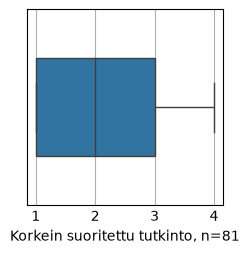

In [2721]:
bp1 = sns.boxplot(x = df2['koulutus'],width=.5)

bp1.set_xlabel('Korkein suoritettu tutkinto, n=' + str(df2['koulutus'].count()))

Katsotaan vielä jakaumaa prosenttien kannalta

In [2722]:
dfePros = pd.crosstab(df2['koulutus'], 'kpl')
dfePros['%'] = dfePros['kpl'] / dfePros['kpl'].sum() * 100
dfePros.index=['Peruskoulu', 'Toinen aste', 'Kanditaatti', 'Maisteri']
dfePros.columns.name='Suoritetun tutkinnon taso'
dfePros

Suoritetun tutkinnon taso,kpl,%
Peruskoulu,27,33.333333
Toinen aste,30,37.037037
Kanditaatti,22,27.160494
Maisteri,2,2.469136


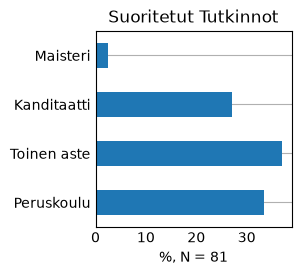

In [2723]:
dfePros['%'].plot.barh(zorder = 2)
plt.title('Suoritetut Tutkinnot')
plt.xlabel('%, N = ' + str(dfePros['kpl'].sum()))
plt.grid(axis = 'x')
plt.tick_params(axis = 'y', length = 0)


#### Havainnot koulutuksesta:
- Yleisellä tasolla heräisi kysymys maistereiden määrästä, onko yrityksessä "epäpäteviä" tai "liian päteviä" tietyissä tehtävissä (Tämähän ei siis vaikuta ovatko he kykeneviä suoriutumaan tehtävästään)
- Muuta merkittävää en omana analyysini pohjalta ole löytänyt
- Datan ainoa "poikkeama" on nämä kaksi maisteria, joka johtaa että keskiarvo & Boxplot on juuri sitä mitä olettaa

### Salary numeerinen muttuja

Palkkojen keskiarvo, minimi, maksimi ja poikkeama <br>
Erikseen kirjattu mediaani, koska se puuttui taulukosta

In [2724]:
dfp = df2
s_mediaani = dfp['palkka'].median()
print("Palkan mediaani on  {:.0f}".format(s_mediaani))
dfp.describe()[["palkka"]]

Palkan mediaani on  2320


,palkka
count,82.000000
mean,2563.878049
std,849.350302
min,1521.000000
25%,2027.000000
50%,2320.000000
75%,2808.000000
max,6278.000000


Luodaan numeeriselle muuttujalle "palkka" luokitelluksimuuttujaksi "palkkataso"

In [2725]:
bins = [1000, 2000, 3000, 4000, 5000, 6000, 7000]
dfp['palkkataso'] = pd.cut(dfp['palkka'], bins = bins)
dfp

,koulutus,palkka,sat_johto,sat_kolleegat,sat_tyoYmparisto,sat_palkka,sat_tyoTehtavat,palkkataso
0,1.0,3587,3,3.0,3,3,3,"(3000, 4000]"
1,2.0,2963,1,5.0,2,1,3,"(2000, 3000]"
2,1.0,1989,3,4.0,1,1,3,"(1000, 2000]"
3,1.0,2144,3,3.0,3,3,3,"(2000, 3000]"
4,2.0,2183,2,3.0,2,1,2,"(2000, 3000]"
...,...,...,...,...,...,...,...,...
77,3.0,1598,4,4.0,4,3,4,"(1000, 2000]"
78,1.0,1638,1,3.0,2,1,2,"(1000, 2000]"
79,2.0,2612,3,4.0,3,3,3,"(2000, 3000]"
80,2.0,2808,3,4.0,3,3,3,"(2000, 3000]"


Tarkistetaan palkkatasojen prosentti osuudet

In [2726]:
dfpPros = pd.crosstab(dfp['palkkataso'], 'kpl')
dfpPros.columns.name = ' '
n = dfpPros['kpl'].sum()
dfpPros['%'] = dfpPros / n * 100
dfpPros

,kpl,%
palkkataso,,
"(1000, 2000]",19,23.170732
"(2000, 3000]",50,60.975610
"(3000, 4000]",8,9.756098
"(4000, 5000]",2,2.439024
"(5000, 6000]",2,2.439024
"(6000, 7000]",1,1.219512


Vaihdetaan data tyyppi String muotoon, jotta saamme laskettua "yhteensä" rivin

In [2727]:
type(dfpPros.index.values[0])

pandas.Interval

In [2728]:
dfpPros.index = dfpPros.index.astype(str)
dfpPros.loc['Yhteensä'] = dfpPros.sum()
dfpPros

,kpl,%
palkkataso,,
"(1000, 2000]",19.0,23.170732
"(2000, 3000]",50.0,60.975610
"(3000, 4000]",8.0,9.756098
"(4000, 5000]",2.0,2.439024
"(5000, 6000]",2.0,2.439024
"(6000, 7000]",1.0,1.219512
Yhteensä,82.0,100.000000


In [2729]:
type(dfpPros.index.values[0])

str

#### Boxplot

Text(0.5, 0, 'Palkka, n=82')

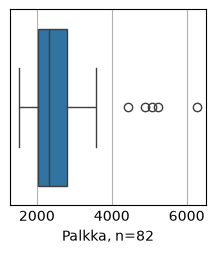

In [2730]:
bp2 = sns.boxplot(x = dfp['palkka'])

bp2.set_xlabel('Palkka, n=' + str(dfp['palkka'].count()))

Kaaviot

Text(0, 0.5, 'kappale määrä, n=82')

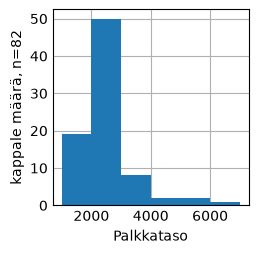

In [2731]:
dfp['palkka'].hist(bins = bins)
plt.xlabel('Palkkataso')
plt.ylabel('kappale määrä, n=' + str(n))

Text(0, 0.5, '%, n =82')

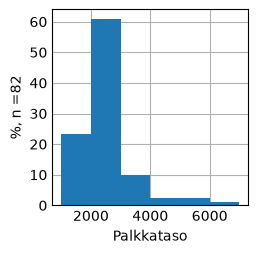

In [2732]:
dfp['palkka'].hist(bins = bins, weights = np.ones(n) / n * 100)

plt.xlabel('Palkkataso')
plt.ylabel('%, n =' + str(n))

Tarkastellaan tarkemmin suurinta palkkaluokan jakaumaa 2000-3000

In [2733]:
binsT = [2000, 2250, 2500, 2750, 3000]
dfp['palkkatasoJakauma'] = pd.cut(dfp['palkka'], bins = binsT)
dfpJakauma = pd.crosstab(dfp['palkkatasoJakauma'], 'kpl')
dfpJakauma.columns.name = ' '
n = dfpJakauma['kpl'].sum()
dfpJakauma['%'] = dfpJakauma / n * 100
dfpJakauma

,kpl,%
palkkatasoJakauma,,
"(2000, 2250]",19,38.0
"(2250, 2500]",9,18.0
"(2500, 2750]",11,22.0
"(2750, 3000]",11,22.0


Text(0, 0.5, 'Kpl, n=50')

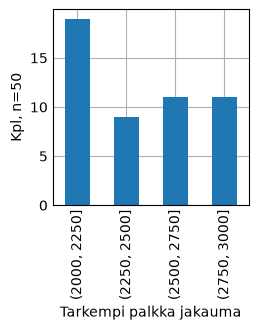

In [2734]:
palkkaJakaumat = pd.cut(dfp['palkka'], bins = binsT, right = True)
palkkaJakaumat.value_counts(sort = False).plot( kind = 'bar')

plt.xlabel('Tarkempi palkka jakauma')
plt.ylabel('Kpl, n=' + str(n))

---

#### Havainnot palkasta:
- Huomioiden että 2808€ kattaa 75% palkoista & suurin palkka on 6278€ osoittaa tarpeen luokittellunmuuttujan "palkkataso" tarpeen, jotta ymmärrämme jakaumaa paremmin
- 1000-3000 palkka jakaumassa on 69/82 henkilöä
- Boxplotista huomataan 5 poikkeamaa ("Palkka" sarake antaa täydellisen esimerkin Boxplotista, josta olen hyvin tyytyväinen. Tämä opetti minulle miten Boxplottia luetaan ja mitä siitä voidaan huomata)
- Jakauma 2000-3000 tulisi vielä jakaa vielä tarkempaan jakaumaan, se kattaa nimittäin 60% kaikista palkoista
- Tarkemmin jakaumaa anaalysoituna huomaamme että 19/50 (38%) on alimmassa jakaumassa eli 2000-2250€

# Sat_Muuttujat

### sat_management eli sat_johto

In [2735]:
dfsj = df

In [2736]:
sj = pd.crosstab(df['sat_johto'], 'kpl')
sj.columns.name=''
sj

,kpl
sat_johto,
1,7
2,16
3,30
4,23
5,6


Text(0.5, 0, 'Net house income, n=82')

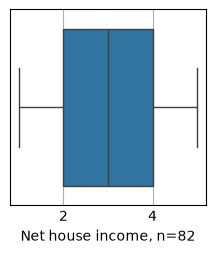

In [2737]:
bp3 = sns.boxplot(x = dfsj['sat_johto'])

bp3.set_xlabel('Net house income, n=' + str(dfsj['sat_johto'].count()))

### sat_colleques eli sat_kolleegat

In [2738]:
dfsk = df

In [2739]:
sk = pd.crosstab(dfsk['sat_kolleegat'], 'kpl')
sk.columns.name=''
sk

,kpl
sat_kolleegat,
2.0,3
3.0,16
4.0,35
5.0,27


Text(0.5, 0, 'Net house income, n=81')

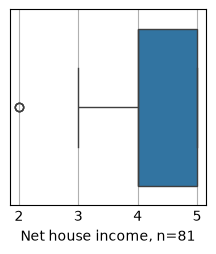

In [2740]:
bp4 = sns.boxplot(x = dfsk['sat_kolleegat'])

bp4.set_xlabel('Net house income, n=' + str(dfsk['sat_kolleegat'].count()))

### sat_workingEnvironment eli sat_tyoYmparisto

In [2741]:
dfstY = df

In [2742]:
stY = pd.crosstab(dfstY['sat_tyoYmparisto'], 'kpl')
stY.columns.name=''
stY

,kpl
sat_tyoYmparisto,
1,9
2,9
3,30
4,23
5,11


Text(0.5, 0, 'Net house income, n=82')

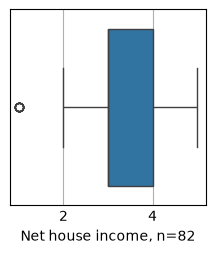

In [2743]:
bp5 = sns.boxplot(x = dfstY['sat_tyoYmparisto'])

bp5.set_xlabel('Net house income, n=' + str(dfstY['sat_tyoYmparisto'].count()))

### sat_salary eli sat_palkka

In [2744]:
dfsp = df

In [2745]:
sp = pd.crosstab(dfsp['sat_palkka'], 'kpl')
sp.columns.name=''
sp

,kpl
sat_palkka,
1,33
2,19
3,19
4,10
5,1


Kappas, vain yksi henkilö on erittäin tyytyväinen palkkaansa<br>
Tulostetaampa tämä rivi niin nähdään millainen kaveri on kyseessä<br>

In [2746]:
dfsp.nlargest(n = 1, columns = 'sat_palkka')

,koulutus,palkka,sat_johto,sat_kolleegat,sat_tyoYmparisto,sat_palkka,sat_tyoTehtavat,palkkataso,palkkatasoJakauma
36,2.0,2729,5,5.0,5,5,5,"(2000, 3000]","(2500, 2750]"


Tämä taitaa olla legendaarinen "kaikki on tosi hyvin, kysely pois alta niin voin jatkaa töitä" tyypin kaveri

Text(0.5, 0, 'Net house income, n=82')

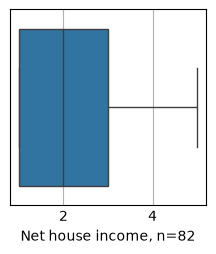

In [2747]:
bp6 = sns.boxplot(x = dfsp['sat_palkka'])

bp6.set_xlabel('Net house income, n=' + str(dfsp['sat_palkka'].count()))

### sat_tasks eli sat_tyoTehtavat


In [2748]:
dfstT = df

In [2749]:
stT = pd.crosstab(dfstT['sat_tyoTehtavat'], 'kpl')
stT.columns.name=''
stT

,kpl
sat_tyoTehtavat,
1,5
2,15
3,29
4,25
5,8


In [2750]:
dfstT.nsmallest(n = 5, columns = 'sat_tyoTehtavat')

,koulutus,palkka,sat_johto,sat_kolleegat,sat_tyoYmparisto,sat_palkka,sat_tyoTehtavat,palkkataso,palkkatasoJakauma
9,1.0,2106,3,2.0,1,1,1,"(2000, 3000]","(2000.0, 2250.0]"
17,3.0,2729,4,3.0,4,2,1,"(2000, 3000]","(2500.0, 2750.0]"
52,1.0,1989,1,2.0,2,1,1,"(1000, 2000]",NaN
74,1.0,1949,1,5.0,1,1,1,"(1000, 2000]",NaN
75,2.0,1598,1,5.0,1,1,1,"(1000, 2000]",NaN


Text(0.5, 0, 'Net house income, n=82')

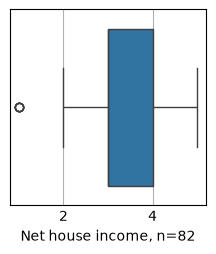

In [2751]:
bp7 = sns.boxplot(x = dfstT['sat_tyoTehtavat'])

bp7.set_xlabel('Net house income, n=' + str(dfstT['sat_tyoTehtavat'].count()))

---

# Muuttuja parien ristiin vertailu

In [2752]:
df.head(1)

,koulutus,palkka,sat_johto,sat_kolleegat,sat_tyoYmparisto,sat_palkka,sat_tyoTehtavat,palkkataso,palkkatasoJakauma
0,1.0,3587,3,3.0,3,3,3,"(3000, 4000]",NaN


In [2753]:
df['koulutus'] = df['koulutus'].astype('Int64')
df['sat_kolleegat'] = df['sat_kolleegat'].astype('Int64')

In [2754]:
df = df.drop(columns=['palkkatasoJakauma'])
df.head(1)

,koulutus,palkka,sat_johto,sat_kolleegat,sat_tyoYmparisto,sat_palkka,sat_tyoTehtavat,palkkataso
0,1,3587,3,3,3,3,3,"(3000, 4000]"


### Koulutus & sat_johto

Prosenteilla

In [2755]:
dfksjP = df
dfksjP = pd.crosstab(dfksjP['koulutus'], dfksjP['sat_johto'], normalize = 'columns') * 100
dfksjP.index = ['Peruskoulu', 'Toinen aste', 'Kanditaatti', 'Maisteri']
dfksjP.columns = ['Erittäin tyytymätön', 'Tyytymätön', 'Neutraali', 'Tyytyväinen', 'Erittäin tyytyväinen']
dfksjP.columns.name='%'
dfksjP


%,Erittäin tyytymätön,Tyytymätön,Neutraali,Tyytyväinen,Erittäin tyytyväinen
Peruskoulu,71.428571,18.75,33.333333,27.272727,50.000000
Toinen aste,28.571429,50.00,36.666667,36.363636,16.666667
Kanditaatti,0.000000,31.25,26.666667,36.363636,16.666667
Maisteri,0.000000,0.00,3.333333,0.000000,16.666667


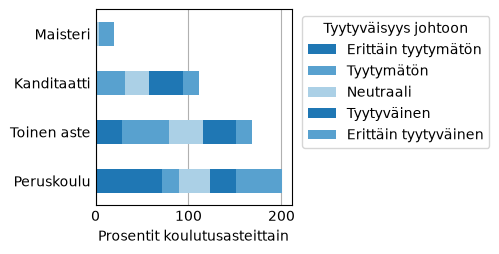

In [2756]:
dfksjP.plot.barh(legend = 'reverse', stacked = 'True')
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left', title='Tyytyväisyys johtoon')
plt.xlabel('Prosentit koulutusasteittain')
plt.grid(axis = 'y')

Kokonaisluvuilla

In [2757]:
dfksjK = df
dfksjK = pd.crosstab(dfksjK['koulutus'], dfksjK['sat_johto'])
dfksjK.index = ['Peruskoulu', 'Toinen aste', 'Kanditaatti', 'Maisteri']
dfksjK.columns = ['Erittäin tyytymätön', 'Tyytymätön', 'Neutraali', 'Tyytyväinen', 'Erittäin tyytyväinen']
dfksjK.columns.name=''
dfksjK

,Erittäin tyytymätön,Tyytymätön,Neutraali,Tyytyväinen,Erittäin tyytyväinen
Peruskoulu,5,3,10,6,3
Toinen aste,2,8,11,8,1
Kanditaatti,0,5,8,8,1
Maisteri,0,0,1,0,1


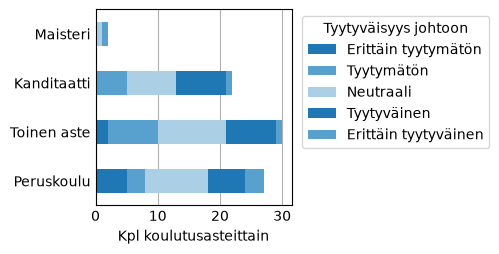

In [2758]:
dfksjK.plot.barh(legend = 'reverse', stacked = 'True')
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left', title='Tyytyväisyys johtoon')
plt.xlabel('Kpl koulutusasteittain')
plt.grid(axis = 'y')

Puhdistetaan 3/4 nollaa pois

In [2759]:
dfksjK_yhdistety = dfksjK.copy()
dfksjK_yhdistety['Tyytymätön'] += dfksjK_yhdistety['Erittäin tyytymätön']
dfksjK_yhdistety['Tyytyväinen'] += dfksjK_yhdistety['Erittäin tyytyväinen']
dfksjK_yhdistety = dfksjK_yhdistety.drop(columns=['Erittäin tyytymätön', 'Erittäin tyytyväinen'])

dfksjK_yhdistety.columns = ['Tyytymätön', 'Neutraali', 'Tyytyväinen']
dfksjK_yhdistety

,Tyytymätön,Neutraali,Tyytyväinen
Peruskoulu,8,10,9
Toinen aste,10,11,9
Kanditaatti,5,8,9
Maisteri,0,1,1


Haetaan p-arvo

In [2760]:
chi2_contingency(dfksjK_yhdistety)

Chi2ContingencyResult(statistic=np.float64(1.7701665725578768), pvalue=np.float64(0.9395767840440443), dof=6, expected_freq=array([[ 7.66666667, 10.        ,  9.33333333],
       [ 8.51851852, 11.11111111, 10.37037037],
       [ 6.24691358,  8.14814815,  7.60493827],
       [ 0.56790123,  0.74074074,  0.69135802]]))

#### Havainnot:
- P-arvo: 0.939
- Ei ole nähtävissä että koulutus vaikuttaisi tyytyväisyyteen esihenkilöihin
- 

### Koulutus & sat_kolleegat

Prosenteilla

In [2761]:
dfkskP = df
dfkskP = pd.crosstab(dfkskP['koulutus'], dfkskP['sat_kolleegat'], normalize = 'columns') * 100
dfkskP.index = ['Peruskoulu', 'Toinen aste', 'Kanditaatti', 'Maisteri']
dfkskP.columns = ['Tyytymätön', 'Neutraali', 'Tyytyväinen', 'Erittäin tyytyväinen']
dfkskP.columns.name='%'
dfkskP

%,Tyytymätön,Neutraali,Tyytyväinen,Erittäin tyytyväinen
Peruskoulu,100.0,31.25,20.588235,44.444444
Toinen aste,0.0,31.25,41.176471,37.037037
Kanditaatti,0.0,37.50,35.294118,14.814815
Maisteri,0.0,0.00,2.941176,3.703704


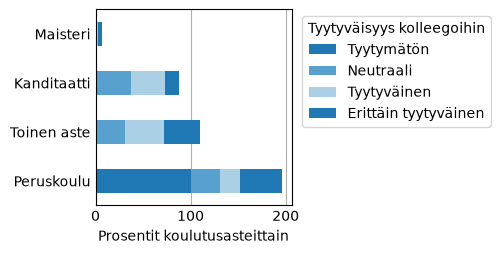

In [2762]:
dfkskP.plot.barh(legend = 'reverse', stacked = 'True')
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left', title='Tyytyväisyys kolleegoihin')
plt.xlabel('Prosentit koulutusasteittain')
plt.grid(axis = 'y')

Kokonaisluvuilla

In [2763]:
dfkskK = df
dfkskK = pd.crosstab(dfkskK['koulutus'], dfkskK['sat_kolleegat'])
dfkskK.index = ['Peruskoulu', 'Toinen aste', 'Kanditaatti', 'Maisteri']
dfkskK.columns = ['Tyytymätön', 'Neutraali', 'Tyytyväinen', 'Erittäin tyytyväinen']
dfkskK.columns.name=''
dfkskK

,Tyytymätön,Neutraali,Tyytyväinen,Erittäin tyytyväinen
Peruskoulu,3,5,7,12
Toinen aste,0,5,14,10
Kanditaatti,0,6,12,4
Maisteri,0,0,1,1


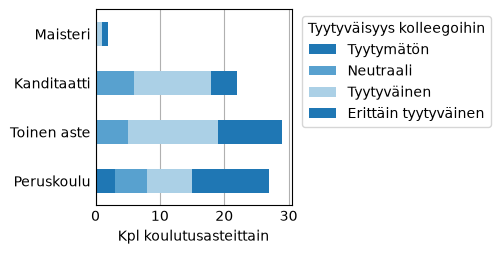

In [2764]:
dfkskK.plot.barh(legend = 'reverse', stacked = 'True')
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left', title='Tyytyväisyys kolleegoihin')
plt.xlabel('Kpl koulutusasteittain')
plt.grid(axis = 'y')

Nollien puhdistus<br>
Taulukosta puuttuu kokonaan "Erittäin tyytymätön" sarake<br>
Taulukkoa katsoessa, en usko tämän taulukon olevan suuresti vaukuttava tekijä esimerkiksi palkkaukseen<br>
Myös sarakkeen lisääminen ei meitä hyödyttäisi, koska saisimme vain 4 kappaletta nollia lisää, ja kun yhdistämme sarakkeet olemme samassa 3-0-0-0 tilanteessa<br>
Jätän kuitenkin ala puolelle p-arvon hakemisen, vaikka meillä onkin 25% nolla arvoja<br>

Haetaan p-arvo

In [2765]:
chi2_contingency(dfkskK)

Chi2ContingencyResult(statistic=np.float64(12.416957494712733), pvalue=np.float64(0.19081048575289153), dof=9, expected_freq=array([[ 1.0125,  5.4   , 11.475 ,  9.1125],
       [ 1.0875,  5.8   , 12.325 ,  9.7875],
       [ 0.825 ,  4.4   ,  9.35  ,  7.425 ],
       [ 0.075 ,  0.4   ,  0.85  ,  0.675 ]]))

#### Havainnot:
- 

### Koulutus & sat_tyoYmparisto

Prosenteilla

In [2766]:
dfkstYP = df
dfkstYP = pd.crosstab(dfkstYP['koulutus'], dfkstYP['sat_tyoYmparisto'], normalize = 'columns') * 100
dfkstYP.index = ['Peruskoulu', 'Toinen aste', 'Kanditaatti', 'Maisteri']
dfkstYP.columns = ['Erittäin tyytymätön','Tyytymätön', 'Neutraali', 'Tyytyväinen', 'Erittäin tyytyväinen']
dfkstYP.columns.name='%'
dfkstYP

%,Erittäin tyytymätön,Tyytymätön,Neutraali,Tyytyväinen,Erittäin tyytyväinen
Peruskoulu,77.777778,33.333333,20.689655,39.130435,18.181818
Toinen aste,22.222222,66.666667,44.827586,13.043478,54.545455
Kanditaatti,0.000000,0.000000,31.034483,47.826087,18.181818
Maisteri,0.000000,0.000000,3.448276,0.000000,9.090909


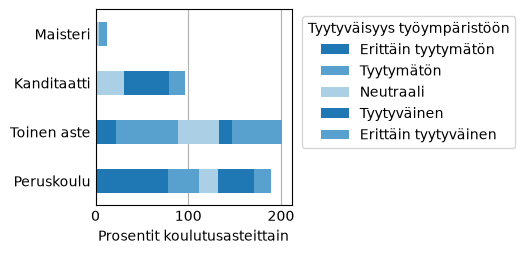

In [2767]:
dfkstYP.plot.barh(legend = 'reverse', stacked = 'True')
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left', title='Tyytyväisyys työympäristöön')
plt.xlabel('Prosentit koulutusasteittain')
plt.grid(axis = 'y')

Kokonaisluvuilla

In [2768]:
dfkstYK = df
dfkstYK = pd.crosstab(dfkstYK['koulutus'], dfkstYK['sat_tyoYmparisto'])
dfkstYK.index = ['Peruskoulu', 'Toinen aste', 'Kanditaatti', 'Maisteri']
dfkstYK.columns = ['Erittäin tyytymätön','Tyytymätön', 'Neutraali', 'Tyytyväinen', 'Erittäin tyytyväinen']
dfkstYK.columns.name=''
dfkstYK

,Erittäin tyytymätön,Tyytymätön,Neutraali,Tyytyväinen,Erittäin tyytyväinen
Peruskoulu,7,3,6,9,2
Toinen aste,2,6,13,3,6
Kanditaatti,0,0,9,11,2
Maisteri,0,0,1,0,1


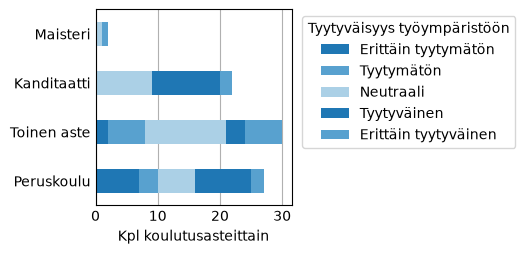

In [2769]:
dfkstYK.plot.barh(legend = 'reverse', stacked = 'True')
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left', title='Tyytyväisyys työympäristöön')
plt.xlabel('Kpl koulutusasteittain')
plt.grid(axis = 'y')

Puhdistetaan 3/5 nollaa pois

In [2770]:
dfkstYK_yhdistety = dfkstYK.copy()
dfkstYK_yhdistety['Tyytymätön'] += dfkstYK_yhdistety['Erittäin tyytymätön']
dfkstYK_yhdistety['Tyytyväinen'] += dfkstYK_yhdistety['Erittäin tyytyväinen']
dfkstYK_yhdistety = dfkstYK_yhdistety.drop(columns=['Erittäin tyytymätön', 'Erittäin tyytyväinen'])

dfkstYK_yhdistety.columns = ['Tyytymätön', 'Neutraali', 'Tyytyväinen']
dfkstYK_yhdistety

,Tyytymätön,Neutraali,Tyytyväinen
Peruskoulu,10,6,11
Toinen aste,8,13,9
Kanditaatti,0,9,13
Maisteri,0,1,1


Haetaan p-arvo<br>
Ennen nollien poistamista, meillä oli p-arvona 0.06....<br>
Nollien putsauksen jälkeen saimme 0.04<br>

In [2771]:
chi2_contingency(dfkstYK_yhdistety)

Chi2ContingencyResult(statistic=np.float64(13.006340279058332), pvalue=np.float64(0.042935373196160614), dof=6, expected_freq=array([[ 6.        ,  9.66666667, 11.33333333],
       [ 6.66666667, 10.74074074, 12.59259259],
       [ 4.88888889,  7.87654321,  9.2345679 ],
       [ 0.44444444,  0.71604938,  0.83950617]]))

#### Havainnot:
- 

### Koulutus & sat_palkka

Prosenteilla

In [2772]:
dfkspP = df
dfkspP = pd.crosstab(dfkspP['koulutus'], dfkspP['sat_palkka']) # normalize = 'columns') * 100
dfkspP.index = ['Peruskoulu', 'Toinen aste', 'Kanditaatti', 'Maisteri']
dfkspP.columns = ['Erittäin tyytymätön','Tyytymätön', 'Neutraali', 'Tyytyväinen', 'Erittäin tyytyväinen']
dfkspP.columns.name='%'
dfkspP

%,Erittäin tyytymätön,Tyytymätön,Neutraali,Tyytyväinen,Erittäin tyytyväinen
Peruskoulu,14,6,5,2,0
Toinen aste,12,8,8,1,1
Kanditaatti,7,4,5,6,0
Maisteri,0,1,0,1,0


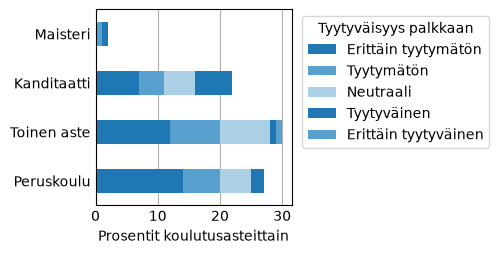

In [2773]:
dfkspP.plot.barh(legend = 'reverse', stacked = 'True')
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left', title='Tyytyväisyys palkkaan')
plt.xlabel('Prosentit koulutusasteittain')
plt.grid(axis = 'y')

Kokonaisluvuilla

In [2774]:
dfkspK = df
dfkspK = pd.crosstab(dfkspK['koulutus'], dfkspK['sat_palkka'])
dfkspK.index = ['Peruskoulu', 'Toinen aste', 'Kanditaatti', 'Maisteri']
dfkspK.columns = ['Erittäin tyytymätön','Tyytymätön', 'Neutraali', 'Tyytyväinen', 'Erittäin tyytyväinen']
dfkspK.columns.name=''
dfkspK

,Erittäin tyytymätön,Tyytymätön,Neutraali,Tyytyväinen,Erittäin tyytyväinen
Peruskoulu,14,6,5,2,0
Toinen aste,12,8,8,1,1
Kanditaatti,7,4,5,6,0
Maisteri,0,1,0,1,0


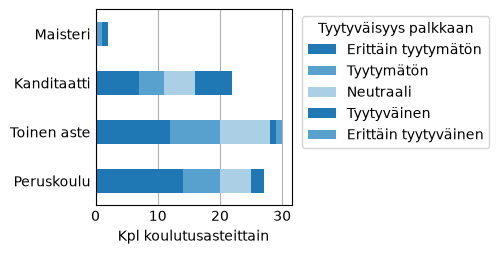

In [2775]:
dfkspK.plot.barh(legend = 'reverse', stacked = 'True')
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left', title='Tyytyväisyys palkkaan')
plt.xlabel('Kpl koulutusasteittain')
plt.grid(axis = 'y')

Puhdistetaan 4/5 nollaa pois

In [2776]:
dfkspK_yhdistety = dfkspK.copy()
dfkspK_yhdistety['Tyytymätön'] += dfkspK_yhdistety['Erittäin tyytymätön']
dfkspK_yhdistety['Tyytyväinen'] += dfkspK_yhdistety['Erittäin tyytyväinen']
dfkspK_yhdistety = dfkspK_yhdistety.drop(columns=['Erittäin tyytymätön', 'Erittäin tyytyväinen'])

dfkspK_yhdistety.columns = ['Tyytymätön', 'Neutraali', 'Tyytyväinen']
dfkspK_yhdistety

,Tyytymätön,Neutraali,Tyytyväinen
Peruskoulu,20,5,2
Toinen aste,20,8,2
Kanditaatti,11,5,6
Maisteri,1,0,1


Haetaan p-arvo

In [2777]:
chi2_contingency(dfkspK)

Chi2ContingencyResult(statistic=np.float64(14.432795418297813), pvalue=np.float64(0.2739284118592917), dof=12, expected_freq=array([[11.        ,  6.33333333,  6.        ,  3.33333333,  0.33333333],
       [12.22222222,  7.03703704,  6.66666667,  3.7037037 ,  0.37037037],
       [ 8.96296296,  5.16049383,  4.88888889,  2.71604938,  0.27160494],
       [ 0.81481481,  0.4691358 ,  0.44444444,  0.24691358,  0.02469136]]))

#### Havainnot:
- 

### Koulutus & sat_tyoTehtavat

Prosenteilla

In [2778]:
dfkstTP = df
dfkstTP = pd.crosstab(dfkstTP['koulutus'], dfkstTP['sat_tyoTehtavat'], normalize = 'columns') * 100
dfkstTP.index = ['Peruskoulu', 'Toinen aste', 'Kanditaatti', 'Maisteri']
dfkstTP.columns = ['Erittäin tyytymätön','Tyytymätön', 'Neutraali', 'Tyytyväinen', 'Erittäin tyytyväinen']
dfkstTP.columns.name='%'
dfkstTP

%,Erittäin tyytymätön,Tyytymätön,Neutraali,Tyytyväinen,Erittäin tyytyväinen
Peruskoulu,60.0,21.428571,44.827586,24.0,25.0
Toinen aste,20.0,57.142857,34.482759,28.0,50.0
Kanditaatti,20.0,14.285714,20.689655,48.0,12.5
Maisteri,0.0,7.142857,0.000000,0.0,12.5


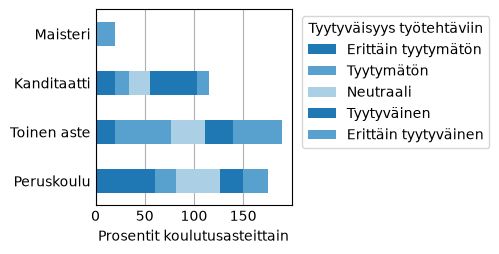

In [2779]:
dfkstTP.plot.barh(legend = 'reverse', stacked = 'True')
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left', title='Tyytyväisyys työtehtäviin')
plt.xlabel('Prosentit koulutusasteittain')
plt.grid(axis = 'y')

Kokonaisluvuilla

In [2780]:
dfkstTK = df
dfkstTK = pd.crosstab(dfkstTK['koulutus'], dfkstTK['sat_tyoTehtavat'])
dfkstTK.index = ['Peruskoulu', 'Toinen aste', 'Kanditaatti', 'Maisteri']
dfkstTK.columns = ['Erittäin tyytymätön','Tyytymätön', 'Neutraali', 'Tyytyväinen', 'Erittäin tyytyväinen']
dfkstTK.columns.name=''
dfkstTK

,Erittäin tyytymätön,Tyytymätön,Neutraali,Tyytyväinen,Erittäin tyytyväinen
Peruskoulu,3,3,13,6,2
Toinen aste,1,8,10,7,4
Kanditaatti,1,2,6,12,1
Maisteri,0,1,0,0,1


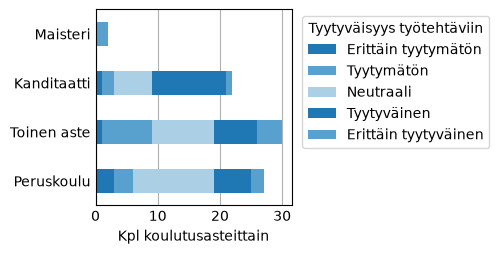

In [2781]:
dfkstTK.plot.barh(legend = 'reverse', stacked = 'True')
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left', title='Tyytyväisyys työtehtäviin')
plt.xlabel('Kpl koulutusasteittain')
plt.grid(axis = 'y')

Puhdistetaan 2/3 nollaa pois

In [2782]:
dfkstTK_yhdistety = dfkstTK.copy()
dfkstTK_yhdistety['Tyytymätön'] += dfkstTK_yhdistety['Erittäin tyytymätön']
dfkstTK_yhdistety['Tyytyväinen'] += dfkstTK_yhdistety['Erittäin tyytyväinen']
dfkstTK_yhdistety = dfkstTK_yhdistety.drop(columns=['Erittäin tyytymätön', 'Erittäin tyytyväinen'])

dfkstTK_yhdistety.columns = ['Tyytymätön', 'Neutraali', 'Tyytyväinen']
dfkstTK_yhdistety

,Tyytymätön,Neutraali,Tyytyväinen
Peruskoulu,6,13,8
Toinen aste,9,10,11
Kanditaatti,3,6,13
Maisteri,1,0,1


Haetaan p-arvo

In [2783]:
chi2_contingency(dfkstTK_yhdistety)

Chi2ContingencyResult(statistic=np.float64(7.23479773814702), pvalue=np.float64(0.2996781446439189), dof=6, expected_freq=array([[ 6.33333333,  9.66666667, 11.        ],
       [ 7.03703704, 10.74074074, 12.22222222],
       [ 5.16049383,  7.87654321,  8.96296296],
       [ 0.4691358 ,  0.71604938,  0.81481481]]))

#### Havainnot:
- 

### palkkataso & sat_johto

Prosenteilla

In [2784]:
dfpsjP = df
dfpsjP = pd.crosstab(dfpsjP['palkkataso'], dfpsjP['sat_johto'], normalize = 'columns') * 100
dfpsjP.index = ['1000, 2000', '2000, 3000', '3000, 4000', '4000, 5000', '5000, 6000', '6000, 7000']
dfpsjP.columns = ['Erittäin tyytymätön', 'Tyytymätön', 'Neutraali', 'Tyytyväinen', 'Erittäin tyytyväinen']
dfpsjP.columns.name='%'
dfpsjP


%,Erittäin tyytymätön,Tyytymätön,Neutraali,Tyytyväinen,Erittäin tyytyväinen
"1000, 2000",57.142857,31.25,13.333333,26.086957,0.000000
"2000, 3000",42.857143,56.25,70.000000,52.173913,83.333333
"3000, 4000",0.000000,6.25,10.000000,17.391304,0.000000
"4000, 5000",0.000000,6.25,3.333333,0.000000,0.000000
"5000, 6000",0.000000,0.00,3.333333,0.000000,16.666667
"6000, 7000",0.000000,0.00,0.000000,4.347826,0.000000


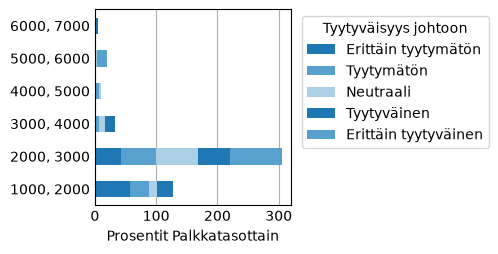

In [2785]:
dfpsjP.plot.barh(legend = 'reverse', stacked = 'True')
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left', title='Tyytyväisyys johtoon')
plt.xlabel('Prosentit Palkkatasottain')
plt.grid(axis = 'y')

Kokonaisluvuilla

In [2786]:
dfpsjK = df
dfpsjK = pd.crosstab(dfpsjK['palkkataso'], dfpsjK['sat_johto'])
dfpsjK.index = ['1000, 2000', '2000, 3000', '3000, 4000', '4000, 5000', '5000, 6000', '6000, 7000']
dfpsjK.columns = ['Erittäin tyytymätön', 'Tyytymätön', 'Neutraali', 'Tyytyväinen', 'Erittäin tyytyväinen']
dfpsjK.columns.name=''
dfpsjK

,Erittäin tyytymätön,Tyytymätön,Neutraali,Tyytyväinen,Erittäin tyytyväinen
"1000, 2000",4,5,4,6,0
"2000, 3000",3,9,21,12,5
"3000, 4000",0,1,3,4,0
"4000, 5000",0,1,1,0,0
"5000, 6000",0,0,1,0,1
"6000, 7000",0,0,0,1,0


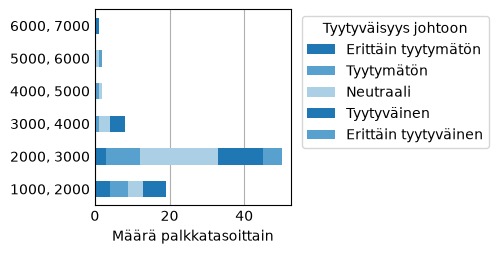

In [2787]:
dfpsjK.plot.barh(legend = 'reverse', stacked = 'True')
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left', title='Tyytyväisyys johtoon')
plt.xlabel('Määrä palkkatasoittain')
plt.grid(axis = 'y')

Puhdistetaan 9/13 nollaa pois

In [2788]:
dfpsjK_yhdistety = dfpsjK.copy()
dfpsjK_yhdistety['Tyytymätön'] += dfpsjK_yhdistety['Erittäin tyytymätön']
dfpsjK_yhdistety['Tyytyväinen'] += dfpsjK_yhdistety['Erittäin tyytyväinen']
dfpsjK_yhdistety = dfpsjK_yhdistety.drop(columns=['Erittäin tyytymätön', 'Erittäin tyytyväinen'])

dfpsjK_yhdistety.columns = ['Tyytymätön', 'Neutraali', 'Tyytyväinen']
dfpsjK_yhdistety

,Tyytymätön,Neutraali,Tyytyväinen
"1000, 2000",9,4,6
"2000, 3000",12,21,17
"3000, 4000",1,3,4
"4000, 5000",1,1,0
"5000, 6000",0,1,1
"6000, 7000",0,0,1


Haetaan p-arvot

13 nollan kanssa: 0.3500<br>
4 nollan kanssa: 0.4844<br>

In [2789]:
chi2_contingency(dfpsjK)

Chi2ContingencyResult(statistic=np.float64(21.825660523591587), pvalue=np.float64(0.35004524211905835), dof=20, expected_freq=array([[ 1.62195122,  3.70731707,  6.95121951,  5.32926829,  1.3902439 ],
       [ 4.26829268,  9.75609756, 18.29268293, 14.02439024,  3.65853659],
       [ 0.68292683,  1.56097561,  2.92682927,  2.24390244,  0.58536585],
       [ 0.17073171,  0.3902439 ,  0.73170732,  0.56097561,  0.14634146],
       [ 0.17073171,  0.3902439 ,  0.73170732,  0.56097561,  0.14634146],
       [ 0.08536585,  0.19512195,  0.36585366,  0.2804878 ,  0.07317073]]))

In [2790]:
chi2_contingency(dfpsjK_yhdistety)

Chi2ContingencyResult(statistic=np.float64(9.510791104447776), pvalue=np.float64(0.484407831836315), dof=10, expected_freq=array([[ 5.32926829,  6.95121951,  6.7195122 ],
       [14.02439024, 18.29268293, 17.68292683],
       [ 2.24390244,  2.92682927,  2.82926829],
       [ 0.56097561,  0.73170732,  0.70731707],
       [ 0.56097561,  0.73170732,  0.70731707],
       [ 0.2804878 ,  0.36585366,  0.35365854]]))

#### Havainnot:
- 

### palkkataso & sat_kolleegat

Prosenteilla

In [2791]:
dfpskP = df
dfpskP = pd.crosstab(dfpskP['palkkataso'], dfpskP['sat_kolleegat'], normalize = 'columns') * 100
dfpskP.index = ['1000, 2000', '2000, 3000', '3000, 4000', '4000, 5000', '5000, 6000', '6000, 7000']
dfpskP.columns = ['Tyytymätön', 'Neutraali', 'Tyytyväinen', 'Erittäin tyytyväinen']
dfpskP.columns.name='%'
dfpskP


%,Tyytymätön,Neutraali,Tyytyväinen,Erittäin tyytyväinen
"1000, 2000",33.333333,31.25,31.428571,7.407407
"2000, 3000",66.666667,62.50,48.571429,77.777778
"3000, 4000",0.000000,6.25,8.571429,11.111111
"4000, 5000",0.000000,0.00,5.714286,0.000000
"5000, 6000",0.000000,0.00,2.857143,3.703704
"6000, 7000",0.000000,0.00,2.857143,0.000000


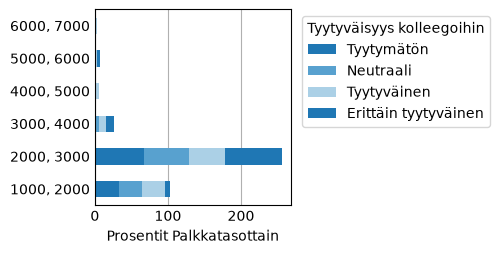

In [2792]:
dfpskP.plot.barh(legend = 'reverse', stacked = 'True')
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left', title='Tyytyväisyys kolleegoihin')
plt.xlabel('Prosentit Palkkatasottain')
plt.grid(axis = 'y')

Kokonaisluvuilla

In [2793]:
dfpskK = df
dfpskK = pd.crosstab(dfpskK['palkkataso'], dfpskK['sat_kolleegat'])
dfpskK.index = ['1000, 2000', '2000, 3000', '3000, 4000', '4000, 5000', '5000, 6000', '6000, 7000']
dfpskK.columns = ['Tyytymätön', 'Neutraali', 'Tyytyväinen', 'Erittäin tyytyväinen']
dfpskK.columns.name=''
dfpskK


,Tyytymätön,Neutraali,Tyytyväinen,Erittäin tyytyväinen
"1000, 2000",1,5,11,2
"2000, 3000",2,10,17,21
"3000, 4000",0,1,3,3
"4000, 5000",0,0,2,0
"5000, 6000",0,0,1,1
"6000, 7000",0,0,1,0


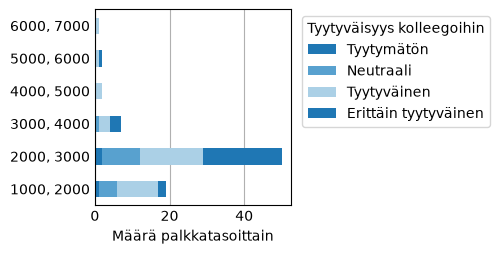

In [2794]:
dfpskK.plot.barh(legend = 'reverse', stacked = 'True')
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left', title='Tyytyväisyys kolleegoihin')
plt.xlabel('Määrä palkkatasoittain')
plt.grid(axis = 'y')

Nollien puhdistus<br>
Taulukosta puuttuu kokonaan "Erittäin tyytymätön" sarake<br>
Taulukkoa katsoessa, en usko tämän taulukon olevan suuresti vaukuttava tekijä esimerkiksi palkkaukseen<br>
Myös sarakkeen lisääminen ei meitä hyödyttäisi, koska saisimme vain 4 kappaletta nollia lisää, ja kun yhdistämme sarakkeet olemme samassa 3-0-0-0 tilanteessa<br>
Jätän kuitenkin ala puolelle p-arvon hakemisen, vaikka meillä onkin 25% nolla arvoja<br>

Haetaan p-arvo

In [2795]:
chi2_contingency(dfpskK)

Chi2ContingencyResult(statistic=np.float64(11.729600429645544), pvalue=np.float64(0.6993701516540636), dof=15, expected_freq=array([[ 0.7037037 ,  3.75308642,  8.20987654,  6.33333333],
       [ 1.85185185,  9.87654321, 21.60493827, 16.66666667],
       [ 0.25925926,  1.38271605,  3.02469136,  2.33333333],
       [ 0.07407407,  0.39506173,  0.86419753,  0.66666667],
       [ 0.07407407,  0.39506173,  0.86419753,  0.66666667],
       [ 0.03703704,  0.19753086,  0.43209877,  0.33333333]]))

#### Havainnot:
- 

### palkkataso & sat_tyoYmparisto

Prosenteilla

In [2796]:
dfpstYP = df
dfpstYP = pd.crosstab(dfpstYP['palkkataso'], dfpstYP['sat_tyoYmparisto'], normalize = 'columns') * 100
dfpstYP.index = ['1000, 2000', '2000, 3000', '3000, 4000', '4000, 5000', '5000, 6000', '6000, 7000']
dfpstYP.columns = ['Erittäin tyytymätön','Tyytymätön', 'Neutraali', 'Tyytyväinen', 'Erittäin tyytyväinen']
dfpstYP.columns.name='%'
dfpstYP

%,Erittäin tyytymätön,Tyytymätön,Neutraali,Tyytyväinen,Erittäin tyytyväinen
"1000, 2000",44.444444,66.666667,16.666667,13.043478,9.090909
"2000, 3000",55.555556,22.222222,63.333333,73.913043,63.636364
"3000, 4000",0.000000,11.111111,10.000000,13.043478,9.090909
"4000, 5000",0.000000,0.000000,6.666667,0.000000,0.000000
"5000, 6000",0.000000,0.000000,3.333333,0.000000,9.090909
"6000, 7000",0.000000,0.000000,0.000000,0.000000,9.090909


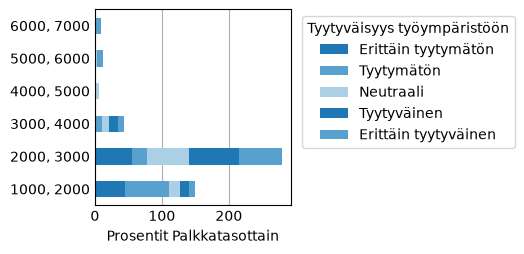

In [2797]:
dfpstYP.plot.barh(legend = 'reverse', stacked = 'True')
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left', title='Tyytyväisyys työympäristöön')
plt.xlabel('Prosentit Palkkatasottain')
plt.grid(axis = 'y')

Kokonaisluvuilla

In [2798]:
dfpstYK = df
dfpstYK = pd.crosstab(dfpstYK['palkkataso'], dfpstYK['sat_tyoYmparisto'])
dfpstYK.index = ['1000, 2000', '2000, 3000', '3000, 4000', '4000, 5000', '5000, 6000', '6000, 7000']
dfpstYK.columns = ['Erittäin tyytymätön','Tyytymätön', 'Neutraali', 'Tyytyväinen', 'Erittäin tyytyväinen']
dfpstYK.columns.name=''
dfpstYK

,Erittäin tyytymätön,Tyytymätön,Neutraali,Tyytyväinen,Erittäin tyytyväinen
"1000, 2000",4,6,5,3,1
"2000, 3000",5,2,19,17,7
"3000, 4000",0,1,3,3,1
"4000, 5000",0,0,2,0,0
"5000, 6000",0,0,1,0,1
"6000, 7000",0,0,0,0,1


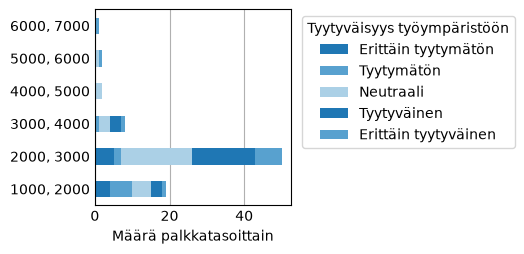

In [2799]:
dfpstYK.plot.barh(legend = 'reverse', stacked = 'True')
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left', title='Tyytyväisyys työympäristöön')
plt.xlabel('Määrä palkkatasoittain')
plt.grid(axis = 'y')

Puhdistetaan 7/12 nollaa

In [2800]:
dfpstYK_yhdistety = dfpstYK.copy()
dfpstYK_yhdistety['Tyytymätön'] += dfpstYK_yhdistety['Erittäin tyytymätön']
dfpstYK_yhdistety['Tyytyväinen'] += dfpstYK_yhdistety['Erittäin tyytyväinen']
dfpstYK_yhdistety = dfpstYK_yhdistety.drop(columns=['Erittäin tyytymätön', 'Erittäin tyytyväinen'])

dfpstYK_yhdistety.columns = ['Tyytymätön', 'Neutraali', 'Tyytyväinen']
dfpstYK_yhdistety

,Tyytymätön,Neutraali,Tyytyväinen
"1000, 2000",10,5,4
"2000, 3000",7,19,24
"3000, 4000",1,3,4
"4000, 5000",0,2,0
"5000, 6000",0,1,1
"6000, 7000",0,0,1


Haetaan p-arvo

In [2801]:
chi2_contingency(dfpstYK_yhdistety)

Chi2ContingencyResult(statistic=np.float64(18.505653938768493), pvalue=np.float64(0.04700990869704083), dof=10, expected_freq=array([[ 4.17073171,  6.95121951,  7.87804878],
       [10.97560976, 18.29268293, 20.73170732],
       [ 1.75609756,  2.92682927,  3.31707317],
       [ 0.43902439,  0.73170732,  0.82926829],
       [ 0.43902439,  0.73170732,  0.82926829],
       [ 0.2195122 ,  0.36585366,  0.41463415]]))

#### Havainnot:
- 

### palkkataso & sat_palkka

Prosenteilla

In [2802]:
dfpspP = df
dfpspP = pd.crosstab(dfpspP['palkkataso'], dfpspP['sat_palkka'], normalize = 'columns') * 100
dfpspP.index = ['1000, 2000', '2000, 3000', '3000, 4000', '4000, 5000', '5000, 6000', '6000, 7000']
dfpspP.columns = ['Erittäin tyytymätön','Tyytymätön', 'Neutraali', 'Tyytyväinen', 'Erittäin tyytyväinen']
dfpspP.columns.name='%'
dfpspP

%,Erittäin tyytymätön,Tyytymätön,Neutraali,Tyytyväinen,Erittäin tyytyväinen
"1000, 2000",27.272727,31.578947,21.052632,0.0,0.0
"2000, 3000",63.636364,52.631579,68.421053,50.0,100.0
"3000, 4000",9.090909,5.263158,10.526316,20.0,0.0
"4000, 5000",0.000000,5.263158,0.000000,10.0,0.0
"5000, 6000",0.000000,5.263158,0.000000,10.0,0.0
"6000, 7000",0.000000,0.000000,0.000000,10.0,0.0


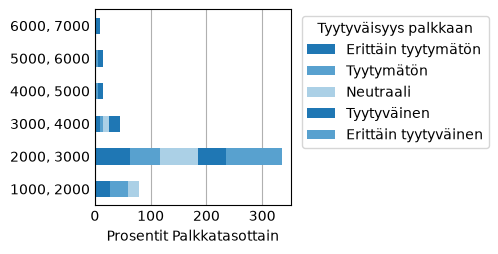

In [2803]:
dfpspP.plot.barh(legend = 'reverse', stacked = 'True')
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left', title='Tyytyväisyys palkkaan')
plt.xlabel('Prosentit Palkkatasottain')
plt.grid(axis = 'y')

Kokonaisluvuilla

In [2804]:
dfpspK = df
dfpspK = pd.crosstab(dfpspK['palkkataso'], dfpspK['sat_palkka'])
dfpspK.index = ['1000, 2000', '2000, 3000', '3000, 4000', '4000, 5000', '5000, 6000', '6000, 7000']
dfpspK.columns = ['Erittäin tyytymätön','Tyytymätön', 'Neutraali', 'Tyytyväinen', 'Erittäin tyytyväinen']
dfpspK.columns.name=''
dfpspK

,Erittäin tyytymätön,Tyytymätön,Neutraali,Tyytyväinen,Erittäin tyytyväinen
"1000, 2000",9,6,4,0,0
"2000, 3000",21,10,13,5,1
"3000, 4000",3,1,2,2,0
"4000, 5000",0,1,0,1,0
"5000, 6000",0,1,0,1,0
"6000, 7000",0,0,0,1,0


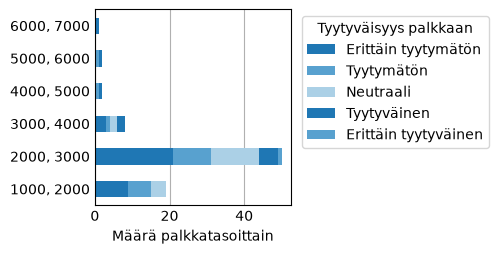

In [2805]:
dfpspK.plot.barh(legend = 'reverse', stacked = 'True')
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left', title='Tyytyväisyys palkkaan')
plt.xlabel('Määrä palkkatasoittain')
plt.grid(axis = 'y')

Puhdistetaan 8/13 nollaa

In [2806]:
dfpspK_yhdistetty = dfpspK.copy()
dfpspK_yhdistetty['Tyytymätön'] += dfpspK_yhdistetty['Erittäin tyytymätön']
dfpspK_yhdistetty['Tyytyväinen'] += dfpspK_yhdistetty['Erittäin tyytyväinen']
dfpspK_yhdistetty = dfpspK_yhdistetty.drop(columns=['Erittäin tyytymätön', 'Erittäin tyytyväinen'])

dfpspK_yhdistetty.columns = ['Tyytymätön', 'Neutraali', 'Tyytyväinen']
dfpspK_yhdistetty

,Tyytymätön,Neutraali,Tyytyväinen
"1000, 2000",15,4,0
"2000, 3000",31,13,6
"3000, 4000",4,2,2
"4000, 5000",1,0,1
"5000, 6000",1,0,1
"6000, 7000",0,0,1


Haetaan p-arvo

In [2807]:
chi2_contingency(dfpspK_yhdistetty)

Chi2ContingencyResult(statistic=np.float64(16.096568390058696), pvalue=np.float64(0.09690118760759767), dof=10, expected_freq=array([[12.04878049,  4.40243902,  2.54878049],
       [31.70731707, 11.58536585,  6.70731707],
       [ 5.07317073,  1.85365854,  1.07317073],
       [ 1.26829268,  0.46341463,  0.26829268],
       [ 1.26829268,  0.46341463,  0.26829268],
       [ 0.63414634,  0.23170732,  0.13414634]]))

#### Havainnot:
- 

### palkkataso & sat_tyoTehtavat

Prosenteilla

In [2808]:
dfpstTP = df
dfpstTP = pd.crosstab(dfpstTP['palkkataso'], dfpstTP['sat_tyoTehtavat'], normalize = 'columns') * 100
dfpstTP.index = ['1000, 2000', '2000, 3000', '3000, 4000', '4000, 5000', '5000, 6000', '6000, 7000']
dfpstTP.columns = ['Erittäin tyytymätön','Tyytymätön', 'Neutraali', 'Tyytyväinen', 'Erittäin tyytyväinen']
dfpstTP.columns.name='%'
dfpstTP

%,Erittäin tyytymätön,Tyytymätön,Neutraali,Tyytyväinen,Erittäin tyytyväinen
"1000, 2000",60.0,20.000000,37.931034,8.0,0.0
"2000, 3000",40.0,66.666667,55.172414,68.0,62.5
"3000, 4000",0.0,6.666667,6.896552,16.0,12.5
"4000, 5000",0.0,0.000000,0.000000,4.0,12.5
"5000, 6000",0.0,6.666667,0.000000,0.0,12.5
"6000, 7000",0.0,0.000000,0.000000,4.0,0.0


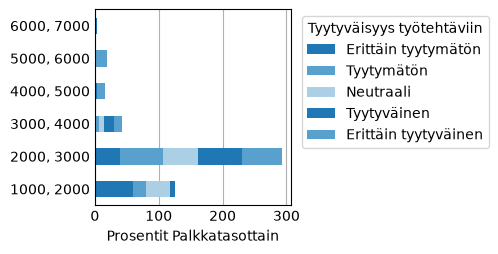

In [2809]:
dfpstTP.plot.barh(legend = 'reverse', stacked = 'True')
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left', title='Tyytyväisyys työtehtäviin')
plt.xlabel('Prosentit Palkkatasottain')
plt.grid(axis = 'y')

Kokonaisluvuilla

In [2810]:
dfpstTK = df
dfpstTK = pd.crosstab(dfpstTK['palkkataso'], dfpstTK['sat_tyoTehtavat'])
dfpstTK.index = ['1000, 2000', '2000, 3000', '3000, 4000', '4000, 5000', '5000, 6000', '6000, 7000']
dfpstTK.columns = ['Erittäin tyytymätön','Tyytymätön', 'Neutraali', 'Tyytyväinen', 'Erittäin tyytyväinen']
dfpstTK.columns.name=''
dfpstTK

,Erittäin tyytymätön,Tyytymätön,Neutraali,Tyytyväinen,Erittäin tyytyväinen
"1000, 2000",3,3,11,2,0
"2000, 3000",2,10,16,17,5
"3000, 4000",0,1,2,4,1
"4000, 5000",0,0,0,1,1
"5000, 6000",0,1,0,0,1
"6000, 7000",0,0,0,1,0


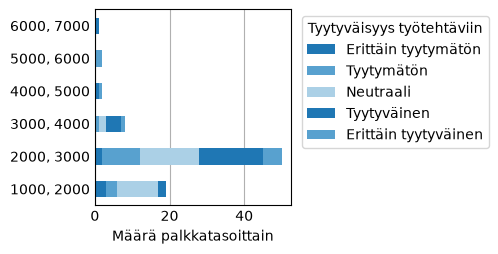

In [2811]:
dfpstTK.plot.barh(legend = 'reverse', stacked = 'True')
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left', title='Tyytyväisyys työtehtäviin')
plt.xlabel('Määrä palkkatasoittain')
plt.grid(axis = 'y')

Puhdistetaan 7/12 nollaa

In [2812]:
dfpstTK_yhdistetty = dfpstTK.copy()
dfpstTK_yhdistetty['Tyytymätön'] += dfpstTK_yhdistetty['Erittäin tyytymätön']
dfpstTK_yhdistetty['Tyytyväinen'] += dfpstTK_yhdistetty['Erittäin tyytyväinen']
dfpstTK_yhdistetty = dfpstTK_yhdistetty.drop(columns=['Erittäin tyytymätön', 'Erittäin tyytyväinen'])

dfpstTK_yhdistetty.columns = ['Tyytymätön', 'Neutraali', 'Tyytyväinen']
dfpstTK_yhdistetty

,Tyytymätön,Neutraali,Tyytyväinen
"1000, 2000",6,11,2
"2000, 3000",12,16,22
"3000, 4000",1,2,5
"4000, 5000",0,0,2
"5000, 6000",1,0,1
"6000, 7000",0,0,1


Haetaan p-arvo

In [2813]:
chi2_contingency(dfpstTK_yhdistetty)

Chi2ContingencyResult(statistic=np.float64(15.075795605785622), pvalue=np.float64(0.1293228239440762), dof=10, expected_freq=array([[ 4.63414634,  6.7195122 ,  7.64634146],
       [12.19512195, 17.68292683, 20.12195122],
       [ 1.95121951,  2.82926829,  3.2195122 ],
       [ 0.48780488,  0.70731707,  0.80487805],
       [ 0.48780488,  0.70731707,  0.80487805],
       [ 0.24390244,  0.35365854,  0.40243902]]))

#### Havainnot:
- 

---

# Reflektointi